# Exploratory Data Analysis and Insights on the Palmer Penguins Dataset Using Pandas

### Beginner-to-Intermediate Pandas Practice Notebook

This notebook is designed for students who are learning how to explore and clean real-world data using **Pandas**.

The exercises begin with basic DataFrame operations and gradually introduce:

- Loading and inspecting a CSV file
- Finding and handling missing values
- Selecting rows and columns
- Exploring categorical values
- Calculating descriptive statistics
- Filtering and sorting records
- Grouping and aggregating data
- Creating derived columns
- Examining correlations
- Creating basic visualizations
- Exporting cleaned data


## About the Dataset

The **PalmerPenguins.csv** dataset contains measurements for **344 penguins** observed on islands in the Palmer Archipelago, Antarctica.

It contains **8 columns**:

| Column | Description |
|---|---|
| `species` | Penguin species: Adelie, Chinstrap, or Gentoo |
| `island` | Island where the penguin was observed |
| `bill_length_mm` | Bill length in millimetres |
| `bill_depth_mm` | Bill depth in millimetres |
| `flipper_length_mm` | Flipper length in millimetres |
| `body_mass_g` | Body mass in grams |
| `sex` | Recorded sex of the penguin |
| `year` | Year of observation |

### Important Observation

The dataset contains some missing values. This gives you an opportunity to practice identifying incomplete records and creating a cleaned DataFrame before performing comparisons and visualizations.

**Source:** [palmerpenguins project](https://allisonhorst.github.io/palmerpenguins/)  
**CSV file:** [Official GitHub repository](https://github.com/allisonhorst/palmerpenguins/blob/main/inst/extdata/penguins.csv)  
**License:** CC0


## Learning Goal

By completing this assignment, you will practice a complete beginner-to-intermediate Pandas workflow. You will inspect data quality, handle missing values, compare penguin groups, create new measurements, explore relationships, and communicate findings with simple charts.


## 1. Loading and Understanding the Dataset

### Question 1
Import the Pandas library using the alias `pd` and read **PalmerPenguins.csv** into a DataFrame named `df`.


In [2]:
import pandas as pd
df = pd.read_csv('D:\Liha-Tech Assignments\Pandas\PalmerPenguins.csv')

### Question 2
Display the first **5 rows** of the dataset.


In [3]:
df.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007


### Question 3
Display the last **5 rows** of the dataset.


In [4]:
df.tail()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
339,Chinstrap,Dream,55.8,19.8,207.0,4000.0,male,2009
340,Chinstrap,Dream,43.5,18.1,202.0,3400.0,female,2009
341,Chinstrap,Dream,49.6,18.2,193.0,3775.0,male,2009
342,Chinstrap,Dream,50.8,19.0,210.0,4100.0,male,2009
343,Chinstrap,Dream,50.2,18.7,198.0,3775.0,female,2009


### Question 4
Find the total number of **rows and columns** in the dataset.


In [5]:
df.shape

(344, 8)

### Question 5
Display all the **column names** in the dataset.


In [6]:
df.columns

Index(['species', 'island', 'bill_length_mm', 'bill_depth_mm',
       'flipper_length_mm', 'body_mass_g', 'sex', 'year'],
      dtype='str')

### Question 6
Display the **data type of each column**.


In [7]:
df.dtypes

species                  str
island                   str
bill_length_mm       float64
bill_depth_mm        float64
flipper_length_mm    float64
body_mass_g          float64
sex                      str
year                   int64
dtype: object

### Question 7
Display a complete summary of the DataFrame using `info()`.


In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    str    
 1   island             344 non-null    str    
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    str    
 7   year               344 non-null    int64  
dtypes: float64(4), int64(1), str(3)
memory usage: 21.6 KB


## 2. Checking and Handling Missing Values

### Question 8
Display the number of **missing values in each column**.


In [9]:
df.isnull().sum()

species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
year                  0
dtype: int64

### Question 9
Calculate the **total number of missing values** in the entire DataFrame.


In [10]:
df.isna().sum().sum()

np.int64(19)

### Question 10
Display every row that contains **at least one missing value**.


In [11]:
df[df.isna().any(axis=1)]

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
8,Adelie,Torgersen,34.1,18.1,193.0,3475.0,NaN,2007
9,Adelie,Torgersen,42.0,20.2,190.0,4250.0,NaN,2007
10,Adelie,Torgersen,37.8,17.1,186.0,3300.0,NaN,2007
11,Adelie,Torgersen,37.8,17.3,180.0,3700.0,NaN,2007
47,Adelie,Dream,37.5,18.9,179.0,2975.0,NaN,2007
178,Gentoo,Biscoe,44.5,14.3,216.0,4100.0,NaN,2007
218,Gentoo,Biscoe,46.2,14.4,214.0,4650.0,NaN,2008
256,Gentoo,Biscoe,47.3,13.8,216.0,4725.0,NaN,2009
268,Gentoo,Biscoe,44.5,15.7,217.0,4875.0,NaN,2009


### Question 11
Create a new DataFrame named `df_clean` by removing rows that contain missing values.


In [12]:
df_clean = df.dropna()

### Question 12
Display the shapes of `df` and `df_clean` to find how many rows were removed.


In [15]:
df.shape
df_clean.shape

(333, 8)

## 3. Selecting Rows and Columns

### Question 13
Select and display only the **species** column from `df_clean`.


In [16]:
df_clean['species']

0         Adelie
1         Adelie
2         Adelie
4         Adelie
5         Adelie
         ...    
339    Chinstrap
340    Chinstrap
341    Chinstrap
342    Chinstrap
343    Chinstrap
Name: species, Length: 333, dtype: str

### Question 14
Select and display the **species, island, and body_mass_g** columns.


In [17]:
df[['species','island','body_mass_g']]

,species,island,body_mass_g
0,Adelie,Torgersen,3750.0
1,Adelie,Torgersen,3800.0
2,Adelie,Torgersen,3250.0
3,Adelie,Torgersen,NaN
4,Adelie,Torgersen,3450.0
...,...,...,...
339,Chinstrap,Dream,4000.0
340,Chinstrap,Dream,3400.0
341,Chinstrap,Dream,3775.0
342,Chinstrap,Dream,4100.0


### Question 15
Display the first **10 rows** of `df_clean` using DataFrame slicing.


In [ ]:
df_clean.loc[0:10]

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007
5,Adelie,Torgersen,39.3,20.6,190.0,3650.0,male,2007
6,Adelie,Torgersen,38.9,17.8,181.0,3625.0,female,2007
7,Adelie,Torgersen,39.2,19.6,195.0,4675.0,male,2007


### Question 16
Using `iloc`, display the first **5 rows and first 4 columns** of `df_clean`.


In [25]:
df_clean.iloc[:5,:4]

,species,island,bill_length_mm,bill_depth_mm
0,Adelie,Torgersen,39.1,18.7
1,Adelie,Torgersen,39.5,17.4
2,Adelie,Torgersen,40.3,18.0
4,Adelie,Torgersen,36.7,19.3
5,Adelie,Torgersen,39.3,20.6


### Question 17
Using `loc`, display rows **10 to 15** for the columns **species, bill_length_mm, flipper_length_mm, and body_mass_g**.


In [28]:
df.loc[10:15,['species', 'bill_length_mm', 'flipper_length_mm','body_mass_g']]

,species,bill_length_mm,flipper_length_mm,body_mass_g
10,Adelie,37.8,186.0,3300.0
11,Adelie,37.8,180.0,3700.0
12,Adelie,41.1,182.0,3200.0
13,Adelie,38.6,191.0,3800.0
14,Adelie,34.6,198.0,4400.0
15,Adelie,36.6,185.0,3700.0


## 4. Exploring Categories and Descriptive Statistics

### Question 18
Display all the **unique penguin species** in the dataset.


In [32]:
df['species'].unique()

<StringArray>
['Adelie', 'Gentoo', 'Chinstrap']
Length: 3, dtype: str

### Question 19
Count the number of penguins belonging to each species using `value_counts()`.


In [33]:
df['species'].value_counts()

species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64

### Question 20
Display all unique island names and count the number of penguins recorded on each island.


In [46]:
df_clean['island'].unique()
df_clean['island'].value_counts()

island
Biscoe       163
Dream        123
Torgersen     47
Name: count, dtype: int64

### Question 21
Count the values in the **sex** column.


In [47]:
df['sex'].value_counts()

sex
male      168
female    165
Name: count, dtype: int64

### Question 22
Display the unique observation years in sorted order.


In [52]:
df['year'].sort_values().unique()

array([2007, 2008, 2009])

### Question 23
Display descriptive statistics for all numeric columns in `df_clean` using `describe()`.


In [53]:
df_clean.describe()

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,year
count,333.000000,333.000000,333.000000,333.000000,333.000000
mean,43.992793,17.164865,200.966967,4207.057057,2008.042042
std,5.468668,1.969235,14.015765,805.215802,0.812944
min,32.100000,13.100000,172.000000,2700.000000,2007.000000
25%,39.500000,15.600000,190.000000,3550.000000,2007.000000
50%,44.500000,17.300000,197.000000,4050.000000,2008.000000
75%,48.600000,18.700000,213.000000,4775.000000,2009.000000
max,59.600000,21.500000,231.000000,6300.000000,2009.000000


### Question 24
Calculate the overall **mean body mass** of the penguins.


In [54]:
df['body_mass_g'].mean()

np.float64(4201.754385964912)

### Question 25
Find the **minimum and maximum flipper length**.


In [55]:
df['flipper_length_mm'].agg(['min','max'])

min    172.0
max    231.0
Name: flipper_length_mm, dtype: float64

## 5. Filtering and Sorting

### Question 26
Display all penguins whose **body_mass_g is greater than 5000**.


In [58]:
df[df['body_mass_g'] > 5000]

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
153,Gentoo,Biscoe,50.0,16.3,230.0,5700.0,male,2007
155,Gentoo,Biscoe,50.0,15.2,218.0,5700.0,male,2007
156,Gentoo,Biscoe,47.6,14.5,215.0,5400.0,male,2007
159,Gentoo,Biscoe,46.7,15.3,219.0,5200.0,male,2007
161,Gentoo,Biscoe,46.8,15.4,215.0,5150.0,male,2007
...,...,...,...,...,...,...,...,...
267,Gentoo,Biscoe,55.1,16.0,230.0,5850.0,male,2009
269,Gentoo,Biscoe,48.8,16.2,222.0,6000.0,male,2009
273,Gentoo,Biscoe,50.4,15.7,222.0,5750.0,male,2009
274,Gentoo,Biscoe,45.2,14.8,212.0,5200.0,female,2009


### Question 27
Display only the penguins belonging to the **Gentoo** species.


In [60]:
df[df['species'] == 'Gentoo']

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
152,Gentoo,Biscoe,46.1,13.2,211.0,4500.0,female,2007
153,Gentoo,Biscoe,50.0,16.3,230.0,5700.0,male,2007
154,Gentoo,Biscoe,48.7,14.1,210.0,4450.0,female,2007
155,Gentoo,Biscoe,50.0,15.2,218.0,5700.0,male,2007
156,Gentoo,Biscoe,47.6,14.5,215.0,5400.0,male,2007
...,...,...,...,...,...,...,...,...
271,Gentoo,Biscoe,NaN,NaN,NaN,NaN,NaN,2009
272,Gentoo,Biscoe,46.8,14.3,215.0,4850.0,female,2009
273,Gentoo,Biscoe,50.4,15.7,222.0,5750.0,male,2009
274,Gentoo,Biscoe,45.2,14.8,212.0,5200.0,female,2009


### Question 28
Display all **female Adelie** penguins.


In [61]:
df.query('species == "Adelie" and sex == "female"')

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007
6,Adelie,Torgersen,38.9,17.8,181.0,3625.0,female,2007
12,Adelie,Torgersen,41.1,17.6,182.0,3200.0,female,2007
...,...,...,...,...,...,...,...,...
142,Adelie,Dream,32.1,15.5,188.0,3050.0,female,2009
144,Adelie,Dream,37.3,16.8,192.0,3000.0,female,2009
147,Adelie,Dream,36.6,18.4,184.0,3475.0,female,2009
148,Adelie,Dream,36.0,17.8,195.0,3450.0,female,2009


### Question 29
Using `query()`, display penguins whose **bill_length_mm is greater than 45** and **flipper_length_mm is greater than 200**.


In [62]:
df.query('bill_length_mm >45 and flipper_length_mm >200')

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
152,Gentoo,Biscoe,46.1,13.2,211.0,4500.0,female,2007
153,Gentoo,Biscoe,50.0,16.3,230.0,5700.0,male,2007
154,Gentoo,Biscoe,48.7,14.1,210.0,4450.0,female,2007
155,Gentoo,Biscoe,50.0,15.2,218.0,5700.0,male,2007
156,Gentoo,Biscoe,47.6,14.5,215.0,5400.0,male,2007
...,...,...,...,...,...,...,...,...
333,Chinstrap,Dream,49.3,19.9,203.0,4050.0,male,2009
334,Chinstrap,Dream,50.2,18.8,202.0,3800.0,male,2009
336,Chinstrap,Dream,51.9,19.5,206.0,3950.0,male,2009
339,Chinstrap,Dream,55.8,19.8,207.0,4000.0,male,2009


### Question 30
Sort `df_clean` by **body_mass_g in descending order** and display the first 10 rows.


In [63]:
df_clean['body_mass_g'].sort_values(ascending=False).head(10)

169    6300.0
185    6050.0
229    6000.0
269    6000.0
263    5950.0
231    5950.0
267    5850.0
167    5850.0
165    5850.0
219    5800.0
Name: body_mass_g, dtype: float64

### Question 31
Display the **5 penguins with the longest flippers**.


In [67]:
df.sort_values(by='flipper_length_mm',ascending=False).head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
215,Gentoo,Biscoe,54.3,15.7,231.0,5650.0,male,2008
265,Gentoo,Biscoe,51.5,16.3,230.0,5500.0,male,2009
267,Gentoo,Biscoe,55.1,16.0,230.0,5850.0,male,2009
217,Gentoo,Biscoe,49.8,16.8,230.0,5700.0,male,2008
227,Gentoo,Biscoe,48.6,16.0,230.0,5800.0,male,2008


## 6. Grouping and Aggregation

### Question 32
Group `df_clean` by **species** and calculate the mean of the measurement columns.


In [68]:
df_clean.groupby('species')[['bill_length_mm','bill_depth_mm','flipper_length_mm']].mean()

,bill_length_mm,bill_depth_mm,flipper_length_mm
species,,,
Adelie,38.823973,18.347260,190.102740
Chinstrap,48.833824,18.420588,195.823529
Gentoo,47.568067,14.996639,217.235294


### Question 33
Calculate the **average body mass for each species**.


In [69]:
df.groupby('species')['body_mass_g'].mean()

species
Adelie       3700.662252
Chinstrap    3733.088235
Gentoo       5076.016260
Name: body_mass_g, dtype: float64

### Question 34
Calculate the **average body mass for each sex**.


In [70]:
df.groupby('sex')['body_mass_g'].mean()

sex
female    3862.272727
male      4545.684524
Name: body_mass_g, dtype: float64

### Question 35
For each species, calculate the **minimum, maximum, and mean bill length** using `agg()`.


In [71]:
df.groupby('species')['bill_length_mm'].agg(['min','max','mean'])

,min,max,mean
species,,,
Adelie,32.1,46.0,38.791391
Chinstrap,40.9,58.0,48.833824
Gentoo,40.9,59.6,47.504878


### Question 36
Create a frequency table showing the number of penguins for each **species and island** using `pd.crosstab()`.


In [72]:
pd.crosstab(df['species'],df['island'])

island,Biscoe,Dream,Torgersen
species,,,
Adelie,44,56,52
Chinstrap,0,68,0
Gentoo,124,0,0


### Question 37
Determine which species has the **highest average flipper length**.


In [75]:
df.groupby('species')['flipper_length_mm'].mean().idxmax()

'Gentoo'

## 7. Creating and Modifying Columns

### Question 38
Create a new column named **body_mass_kg** by converting `body_mass_g` from grams to kilograms.


In [77]:
df['body_mass_kg'] = df['body_mass_g'] / 1000
df

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year,body_mass_kg
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007,3.750
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007,3.800
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007,3.250
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007,3.450
...,...,...,...,...,...,...,...,...,...
339,Chinstrap,Dream,55.8,19.8,207.0,4000.0,male,2009,4.000
340,Chinstrap,Dream,43.5,18.1,202.0,3400.0,female,2009,3.400
341,Chinstrap,Dream,49.6,18.2,193.0,3775.0,male,2009,3.775
342,Chinstrap,Dream,50.8,19.0,210.0,4100.0,male,2009,4.100


### Question 39
Create a new column named **bill_ratio** by dividing `bill_length_mm` by `bill_depth_mm`.


In [81]:
df['bill_ratio']=df['bill_length_mm'] / df['bill_depth_mm']
df

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year,body_mass_kg,bill_ratio
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007,3.750,2.090909
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007,3.800,2.270115
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007,3.250,2.238889
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007,3.450,1.901554
...,...,...,...,...,...,...,...,...,...,...
339,Chinstrap,Dream,55.8,19.8,207.0,4000.0,male,2009,4.000,2.818182
340,Chinstrap,Dream,43.5,18.1,202.0,3400.0,female,2009,3.400,2.403315
341,Chinstrap,Dream,49.6,18.2,193.0,3775.0,male,2009,3.775,2.725275
342,Chinstrap,Dream,50.8,19.0,210.0,4100.0,male,2009,4.100,2.673684


### Question 40
Create a column named **mass_category** using `apply()` with a `lambda` function. Store `Heavy` when `body_mass_g` is greater than or equal to 4500; otherwise store `Light`.


In [83]:
df['mass_category'] = df['body_mass_g'].apply(lambda x:'Heavy' if x>4500 else 'light')
df

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year,body_mass_kg,bill_ratio,mass_category
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007,3.750,2.090909,light
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007,3.800,2.270115,light
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007,3.250,2.238889,light
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007,NaN,NaN,light
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007,3.450,1.901554,light
...,...,...,...,...,...,...,...,...,...,...,...
339,Chinstrap,Dream,55.8,19.8,207.0,4000.0,male,2009,4.000,2.818182,light
340,Chinstrap,Dream,43.5,18.1,202.0,3400.0,female,2009,3.400,2.403315,light
341,Chinstrap,Dream,49.6,18.2,193.0,3775.0,male,2009,3.775,2.725275,light
342,Chinstrap,Dream,50.8,19.0,210.0,4100.0,male,2009,4.100,2.673684,light


### Question 41
Rename the column **sex** to **penguin_sex** in a new DataFrame named `df_renamed`.


In [86]:
df_renamed=df.rename(columns={'sex':'penguin_sex'})
df_renamed

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,penguin_sex,year,body_mass_kg,bill_ratio,mass_category
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007,3.750,2.090909,light
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007,3.800,2.270115,light
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007,3.250,2.238889,light
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007,NaN,NaN,light
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007,3.450,1.901554,light
...,...,...,...,...,...,...,...,...,...,...,...
339,Chinstrap,Dream,55.8,19.8,207.0,4000.0,male,2009,4.000,2.818182,light
340,Chinstrap,Dream,43.5,18.1,202.0,3400.0,female,2009,3.400,2.403315,light
341,Chinstrap,Dream,49.6,18.2,193.0,3775.0,male,2009,3.775,2.725275,light
342,Chinstrap,Dream,50.8,19.0,210.0,4100.0,male,2009,4.100,2.673684,light


## 8. Correlation, Visualization, and Export

### Question 42
Create and display a **correlation matrix** for the numeric measurement columns.


In [87]:
df.corr(numeric_only=True)

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,year,body_mass_kg,bill_ratio
bill_length_mm,1.000000,-0.235053,0.656181,0.595110,0.054545,0.595110,0.780396
bill_depth_mm,-0.235053,1.000000,-0.583851,-0.471916,-0.060354,-0.471916,-0.784191
flipper_length_mm,0.656181,-0.583851,1.000000,0.871202,0.169675,0.871202,0.805166
body_mass_g,0.595110,-0.471916,0.871202,1.000000,0.042209,1.000000,0.703119
year,0.054545,-0.060354,0.169675,0.042209,1.000000,0.042209,0.058480
body_mass_kg,0.595110,-0.471916,0.871202,1.000000,0.042209,1.000000,0.703119
bill_ratio,0.780396,-0.784191,0.805166,0.703119,0.058480,0.703119,1.000000


### Question 43
Create a **histogram** of `body_mass_g` with an appropriate title and axis labels.


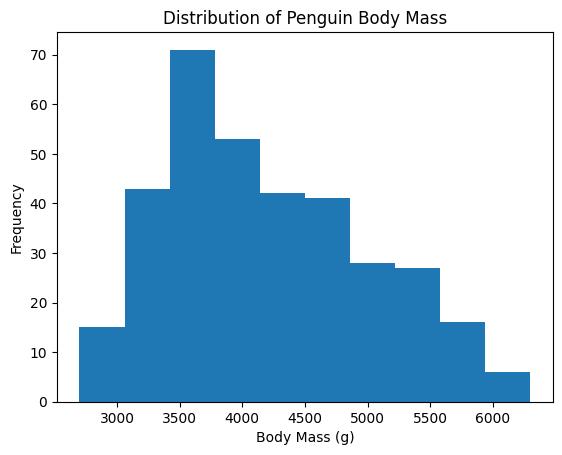

In [89]:
import matplotlib.pyplot as plt

plt.hist(df['body_mass_g'])
plt.title('Distribution of Penguin Body Mass')
plt.xlabel('Body Mass (g)')
plt.ylabel('Frequency')
plt.show()

### Question 44
Create a **bar chart** showing the average `body_mass_g` for each species.


<Axes: xlabel='species', ylabel='body_mass_g'>

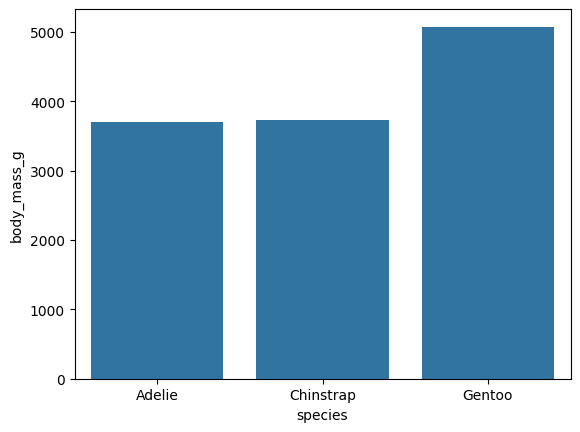

In [96]:
import seaborn as sn
sn.barplot(df.groupby('species')['body_mass_g'].mean())

### Question 45
Create a **box plot** comparing `flipper_length_mm` across the three species.


<Axes: xlabel='species', ylabel='flipper_length_mm'>

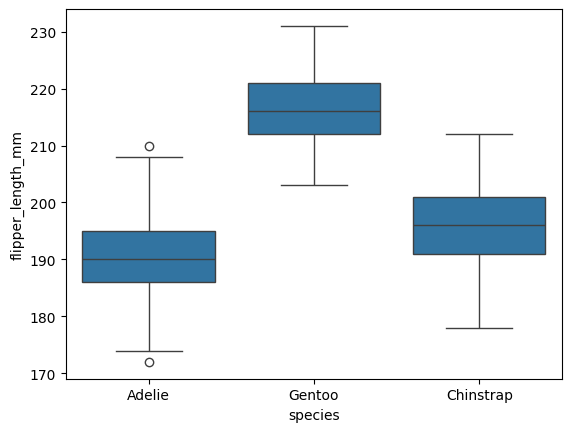

In [98]:
import seaborn as sn

sn.boxplot(x='species', y='flipper_length_mm', data=df)

### Question 46
Create a **scatter plot** of `flipper_length_mm` against `body_mass_g`.


<Axes: xlabel='flipper_length_mm', ylabel='body_mass_g'>

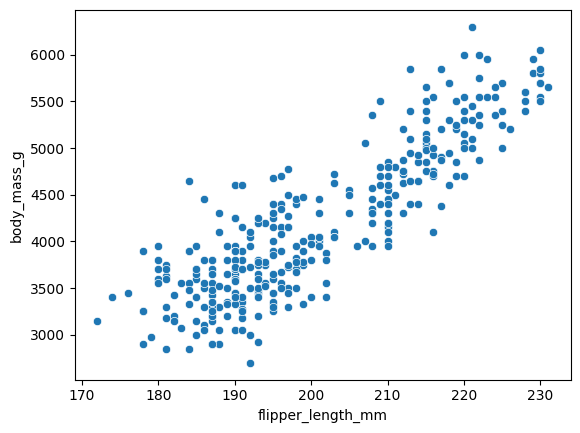

In [99]:
import seaborn as sn
sn.scatterplot(x='flipper_length_mm',y='body_mass_g',data=df)

### Question 47
Save `df_clean` as **PalmerPenguins_Cleaned.csv** using `to_csv()` without saving the index.


In [100]:
df.to_csv('PalmerPenguins_Cleaned.csv',index=False)

## End of Practice

Try to solve each question independently before checking any reference material.

The main goal is to become comfortable with cleaning and exploring a small real-world dataset before moving to more advanced statistical analysis or machine-learning tasks.
